# B2B Telecom Churn Prediction: modelling notebook

**Goal:** predict which **business (B2B) telecom accounts** will terminate all services in the next
**90 days**, and explain why, so account managers and the retention team can act first.

The operator's business unit sells mobile lines, fixed broadband, cloud, IoT and SIP trunking to companies
on 12-month, 24-month or month-to-month contracts.

This notebook is the exploration layer. The production logic lives in `src/` so the notebook, the scoring
job and the Streamlit app all share exactly the same code.

1. Load data
2. Define churn and build snapshots
3. Exploratory analysis
4. Train baseline and LightGBM with a time-based split
5. Evaluate: PR-AUC, lift, calibration
6. Explain with SHAP
7. Score current accounts

*All data is synthetic: a simulated Kuwaiti operator, amounts in KWD.*

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

from src.features import load_raw, build_training_set, FEATURES, NUMERIC_FEATURES, FEATURE_LABELS
from src.config import *

## 1. Load data
Four tables, as they would come from read-only queries on the operator's systems:

| Table | Source system | Grain |
|---|---|---|
| `customers` | CRM | one row per business account, with contract term and start date |
| `monthly_usage` | Billing (BSS) and usage (OSS) | account × month: lines, port-out requests, data, voice, products, MRR |
| `invoices` | Finance | one invoice per account per month |
| `tickets` | Service desk | one row per ticket: category, priority, SLA breach |

In [2]:
tables = load_raw()
for name, df in tables.items():
    print(f"{name:<14} {df.shape}")
tables["customers"].head()

customers      (1500, 10)
monthly_usage  (40757, 14)
invoices       (40757, 6)
tickets        (24759, 7)


,customer_id,company_name,segment,industry,region,account_manager,contract_term,contract_start,status,termination_date
0,T00001,Failaka Solutions 40,SME,Education,Mubarak Al-Kabeer,Account Manager B,12 months,2025-09-29,Active,NaT
1,T00002,Falcon Partners 42,SME,Education,Farwaniya,Account Manager D,Month-to-month,2018-01-04,Terminated,2024-06-20
2,T00003,Palm Group 48,Enterprise,Retail,Hawalli,Account Manager F,24 months,2018-09-29,Terminated,2026-09-01
3,T00004,Falcon Solutions 71,Enterprise,Hospitality,Capital,Account Manager E,Month-to-month,2024-12-16,Terminated,2025-11-25
4,T00005,Desert Group 80,SME,Hospitality,Mubarak Al-Kabeer,Account Manager E,12 months,2019-05-20,Terminated,2024-05-12


In [3]:
tables["monthly_usage"].head()

,customer_id,month,active_lines,lines_added,lines_disconnected,port_out_requests,data_usage_gb,voice_minutes,products_count,has_broadband,has_cloud,has_iot,has_sip,mrr_kwd
0,T00001,2025-09-01,28,2,1,0,164.800,10217,2,0,0,1,0,295.620
1,T00001,2025-10-01,27,0,1,0,203.300,8594,2,0,0,1,0,285.940
2,T00001,2025-11-01,28,1,0,1,173.000,10003,2,0,0,1,0,295.620
3,T00001,2025-12-01,30,2,0,0,179.800,10870,3,1,0,1,0,353.220
4,T00001,2026-01-01,30,0,0,0,165.700,10612,3,1,0,1,0,353.220


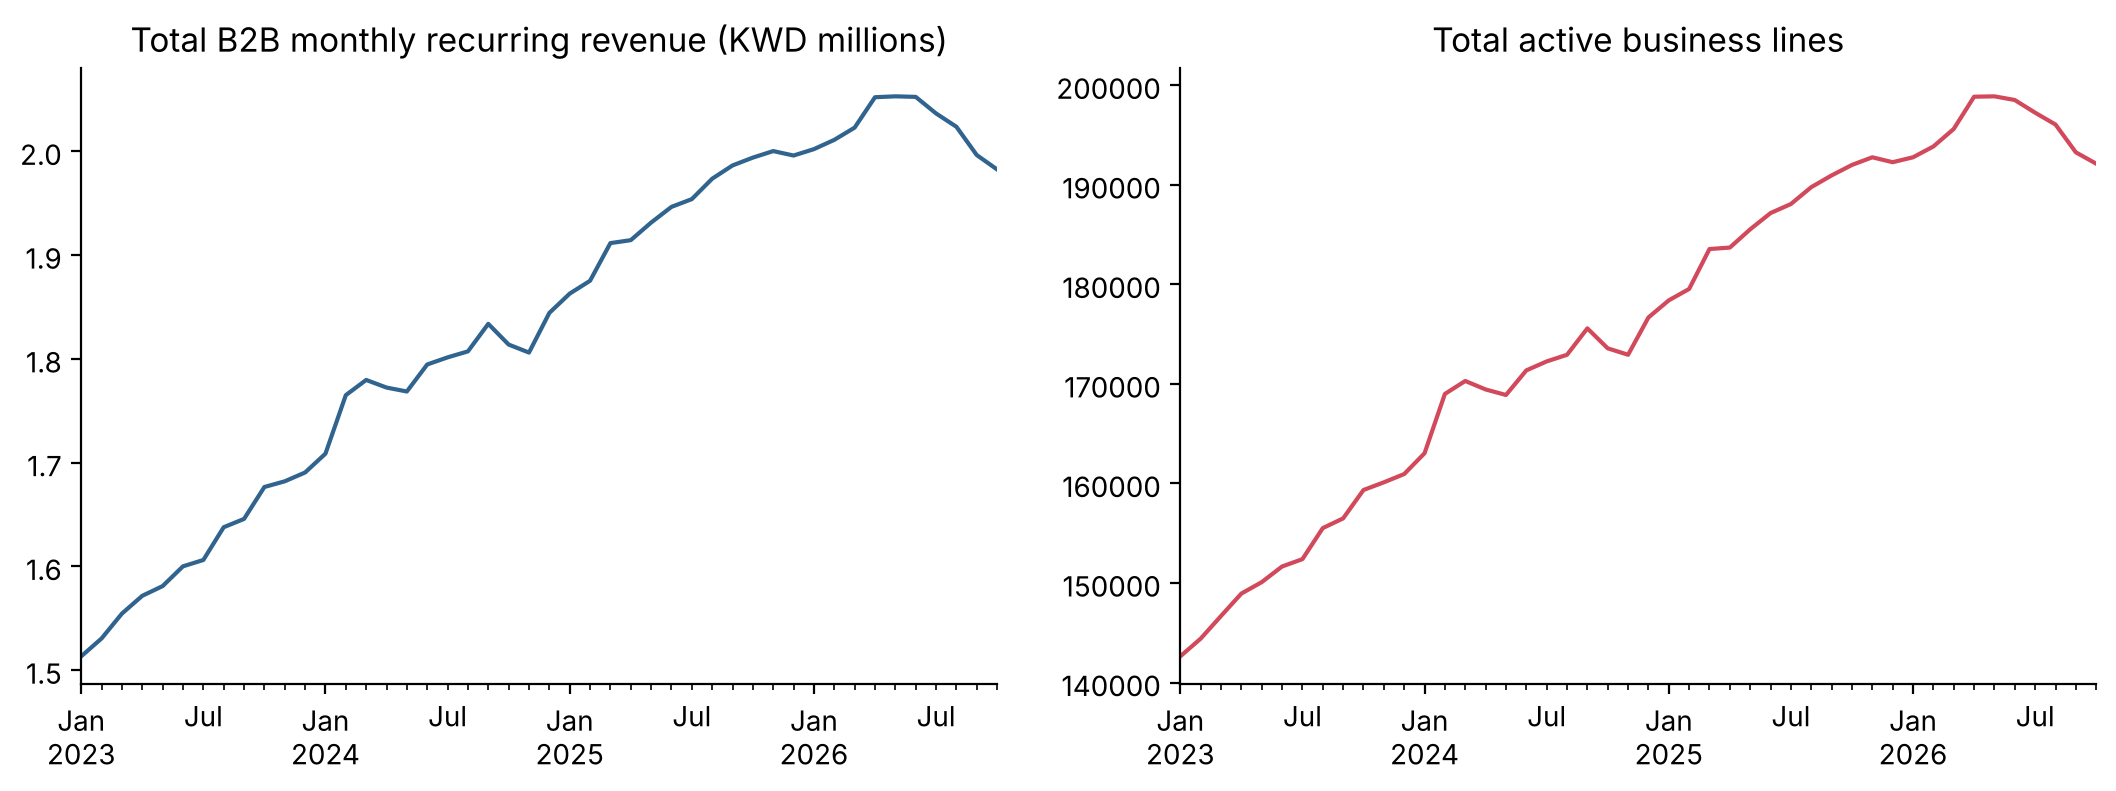

In [4]:
u = tables["monthly_usage"]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
(u.groupby("month")["mrr_kwd"].sum() / 1e6).plot(ax=a, color="#30638E", title="Total B2B monthly recurring revenue (KWD millions)")
u.groupby("month")["active_lines"].sum().plot(ax=b, color="#D1495B", title="Total active business lines")
for ax in (a, b): ax.set_xlabel("")
plt.show()

## 2. Churn definition and snapshots

- **Active** at snapshot date *s*: contract started, not terminated, and billed in that month
- **Churned**: the account **terminates all services** in the 90 days after *s*
- Features use **only** data on or before *s*. `status` and `termination_date` from the CRM are used **only** to build
  the label, never as features.

We take a snapshot at every month-end from 2024-01-31 to 2026-07-31, so each account appears once per month
while active. That gives many more training examples than a single snapshot.

(27470, 31)
Overall 90-day churn rate: 5.1%


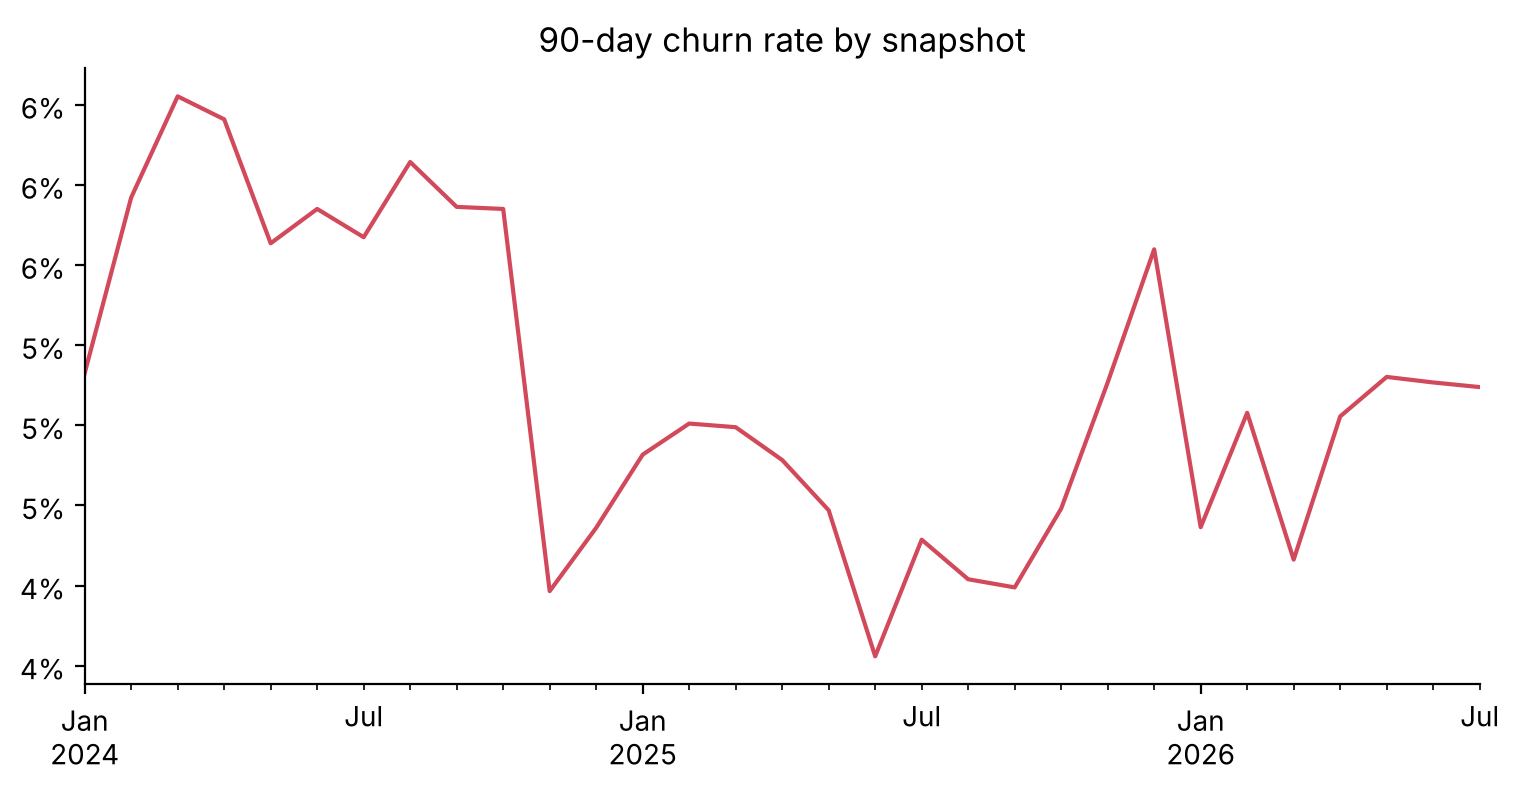

In [5]:
data = build_training_set(tables)
print(data.shape)
print("Overall 90-day churn rate:", f"{data['churned'].mean():.1%}")
data.groupby("snapshot_date")["churned"].mean().plot(title="90-day churn rate by snapshot", color="#D1495B")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); plt.xlabel(""); plt.show()

## 3. Exploratory analysis
How do churners differ from retained accounts *before* they leave?

In [6]:
cols = ["months_to_renewal", "port_out_requests_3m", "lines_change_pct_3m", "data_usage_change_pct",
        "network_tickets_3m", "billing_disputes_3m", "sla_breaches_3m", "avg_days_late_3m", "tenure_months"]
cmp = data.groupby("churned")[cols].mean().T
cmp.columns = ["Retained (mean)", "Churned (mean)"]
cmp.index = [FEATURE_LABELS[c] for c in cmp.index]
cmp

,Retained (mean),Churned (mean)
Months to contract renewal,8.587,2.807
"Port-out requests, last 3 months",0.163,2.988
"Change in lines, last 3 months",0.013,-0.114
Data usage change vs previous 3 months,0.035,-0.145
"Network complaints, last 3 months",0.679,1.293
"Billing disputes, last 3 months",0.175,0.555
"SLA breaches, last 3 months",0.474,1.274
Avg days paid late,3.235,4.287
Tenure (months),40.090,37.669


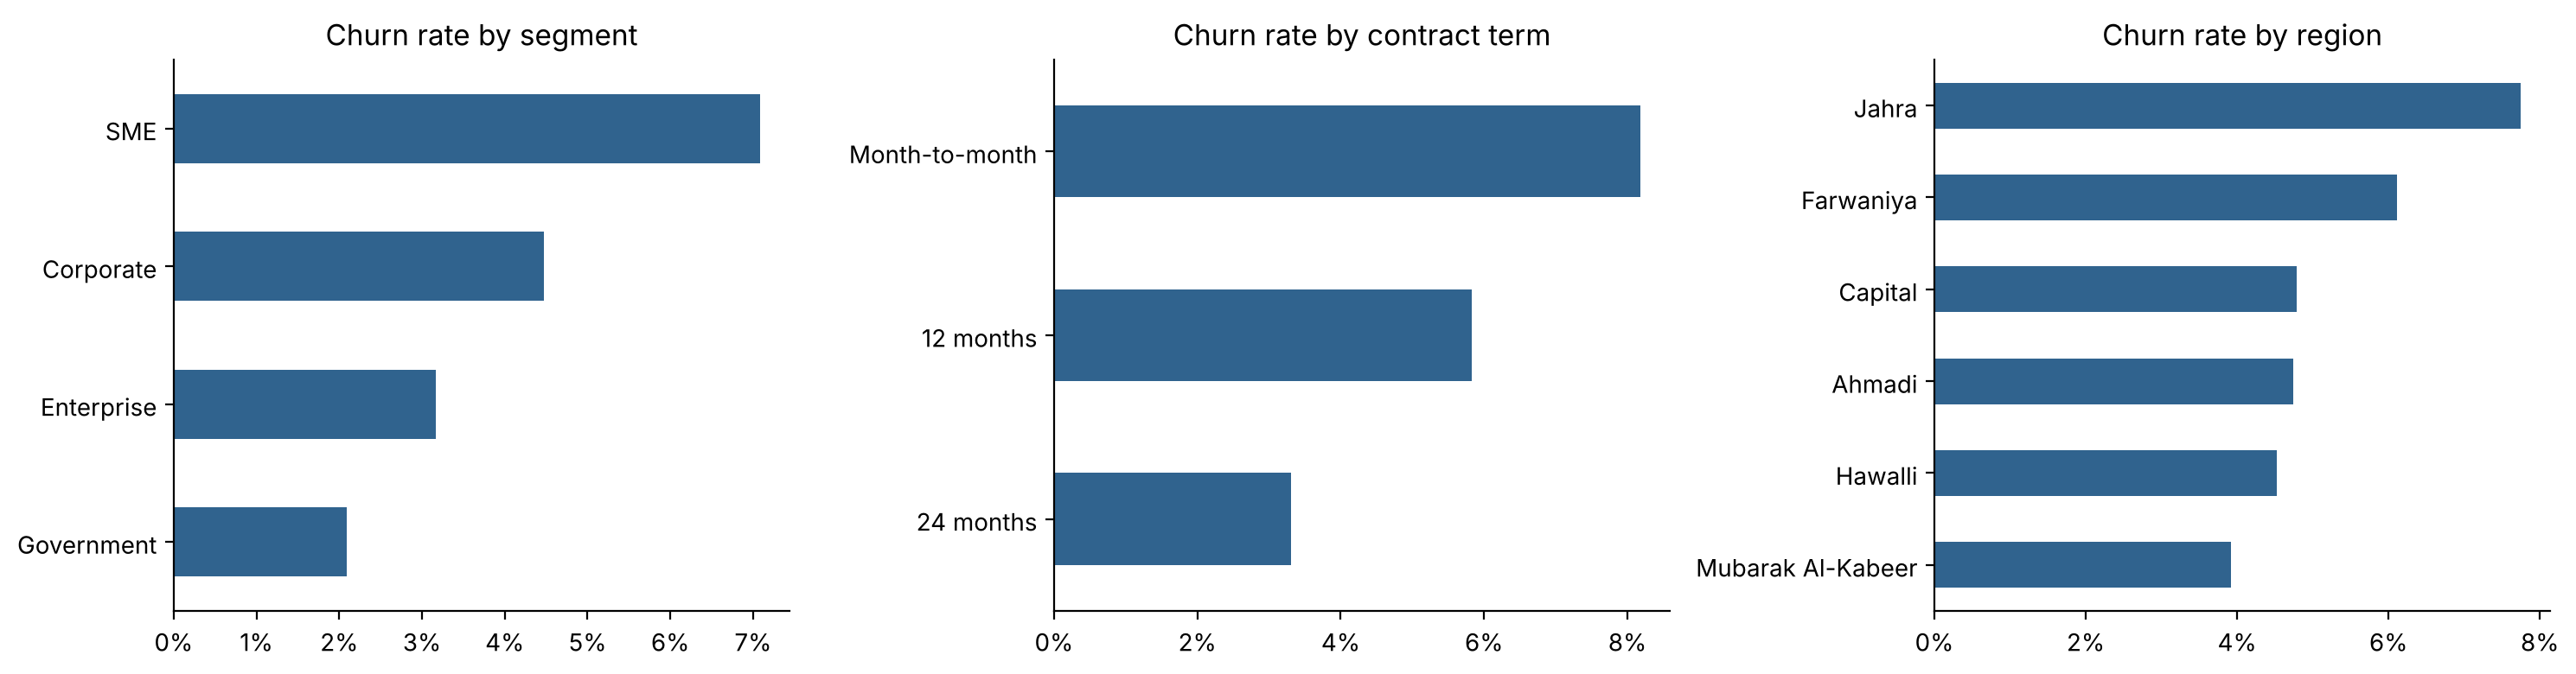

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["segment", "contract_term", "region"]):
    r = data.groupby(col, observed=True)["churned"].mean().sort_values()
    r.plot.barh(ax=ax, color="#30638E", title=f"Churn rate by {col.replace('_', ' ')}")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}")); ax.set_ylabel("")
plt.tight_layout(); plt.show()

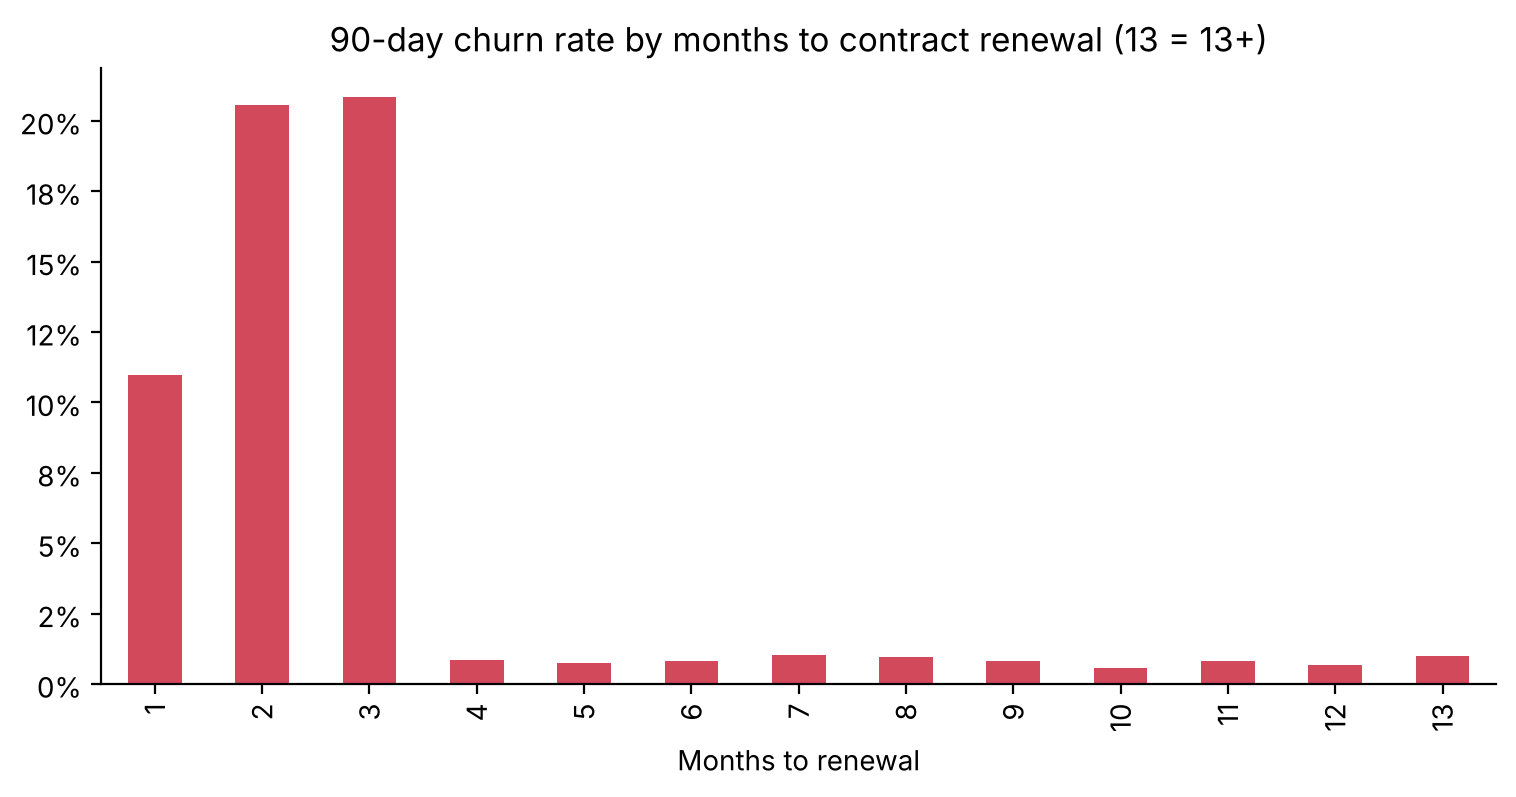

In [8]:
r = data.assign(m=data["months_to_renewal"].clip(upper=13)).groupby("m")["churned"].mean()
ax = r.plot.bar(color="#D1495B", title="90-day churn rate by months to contract renewal (13 = 13+)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.set_xlabel("Months to renewal"); plt.show()

**Takeaways**
- Churn is concentrated in the **3 months before contract renewal**. Inside a contract, early termination is rare.
- **Port-out requests** (numbers moving to another operator) are the clearest early signal. They usually start
  2–4 months before the account leaves.
- Churners also show falling lines and data usage, more network and billing complaints, SLA breaches and later payments.
- SME and month-to-month accounts churn most, and governorates with more network outages (Jahra, Farwaniya) churn more.

## 4. Train: time-based split

A random split would leak future behaviour into training. Instead we train on older snapshots and test on the
most recent ones, with a 90-day gap so no training label overlaps the test period. `src/train.py` does this and
compares a logistic regression baseline with LightGBM.

LightGBM is trained with **monotonic constraints**: more port-outs, complaints, billing disputes, SLA breaches or late payments can only increase predicted risk. This keeps explanations consistent with business logic, even where confounders exist (large accounts log more tickets; regional outages affect healthy accounts).

In [9]:
from src import train
train.main()

{
  "train_rows": 19425,
  "test_rows": 6248,
  "train_snapshots": [
    "2024-01-31",
    "2025-10-31"
  ],
  "test_snapshots": [
    "2026-01-31",
    "2026-07-31"
  ],
  "test_churn_rate": 0.0496,
  "logistic_regression": {
    "roc_auc": 0.915,
    "pr_auc": 0.7023,
    "brier": 0.0224,
    "recall_top_10pct": 0.7161,
    "recall_top_20pct": 0.8065
  },
  "lightgbm": {
    "roc_auc": 0.9417,
    "pr_auc": 0.7303,
    "brier": 0.0213,
    "recall_top_10pct": 0.7387,
    "recall_top_20pct": 0.8806
  }
}

Lift by decile (test):
  decile  accounts  churners  avg_predicted  annual_revenue  churn_rate  lift  cum_share_of_churners
      1       625       229          0.406  10,077,743.040       0.366 7.385                  0.739
      2       625        44          0.050  10,549,170.840       0.070 1.419                  0.881
      3       625        21          0.019  11,770,654.080       0.034 0.677                  0.948
      4       624         9          0.008  11,626,607.160      

## 5. Evaluation

In [10]:
import json
metrics = json.loads((ARTIFACTS_DIR / "metrics.json").read_text())
pd.DataFrame({"Logistic regression": metrics["logistic_regression"], "LightGBM": metrics["lightgbm"]})

,Logistic regression,LightGBM
roc_auc,0.915,0.942
pr_auc,0.702,0.730
brier,0.022,0.021
recall_top_10pct,0.716,0.739
recall_top_20pct,0.806,0.881


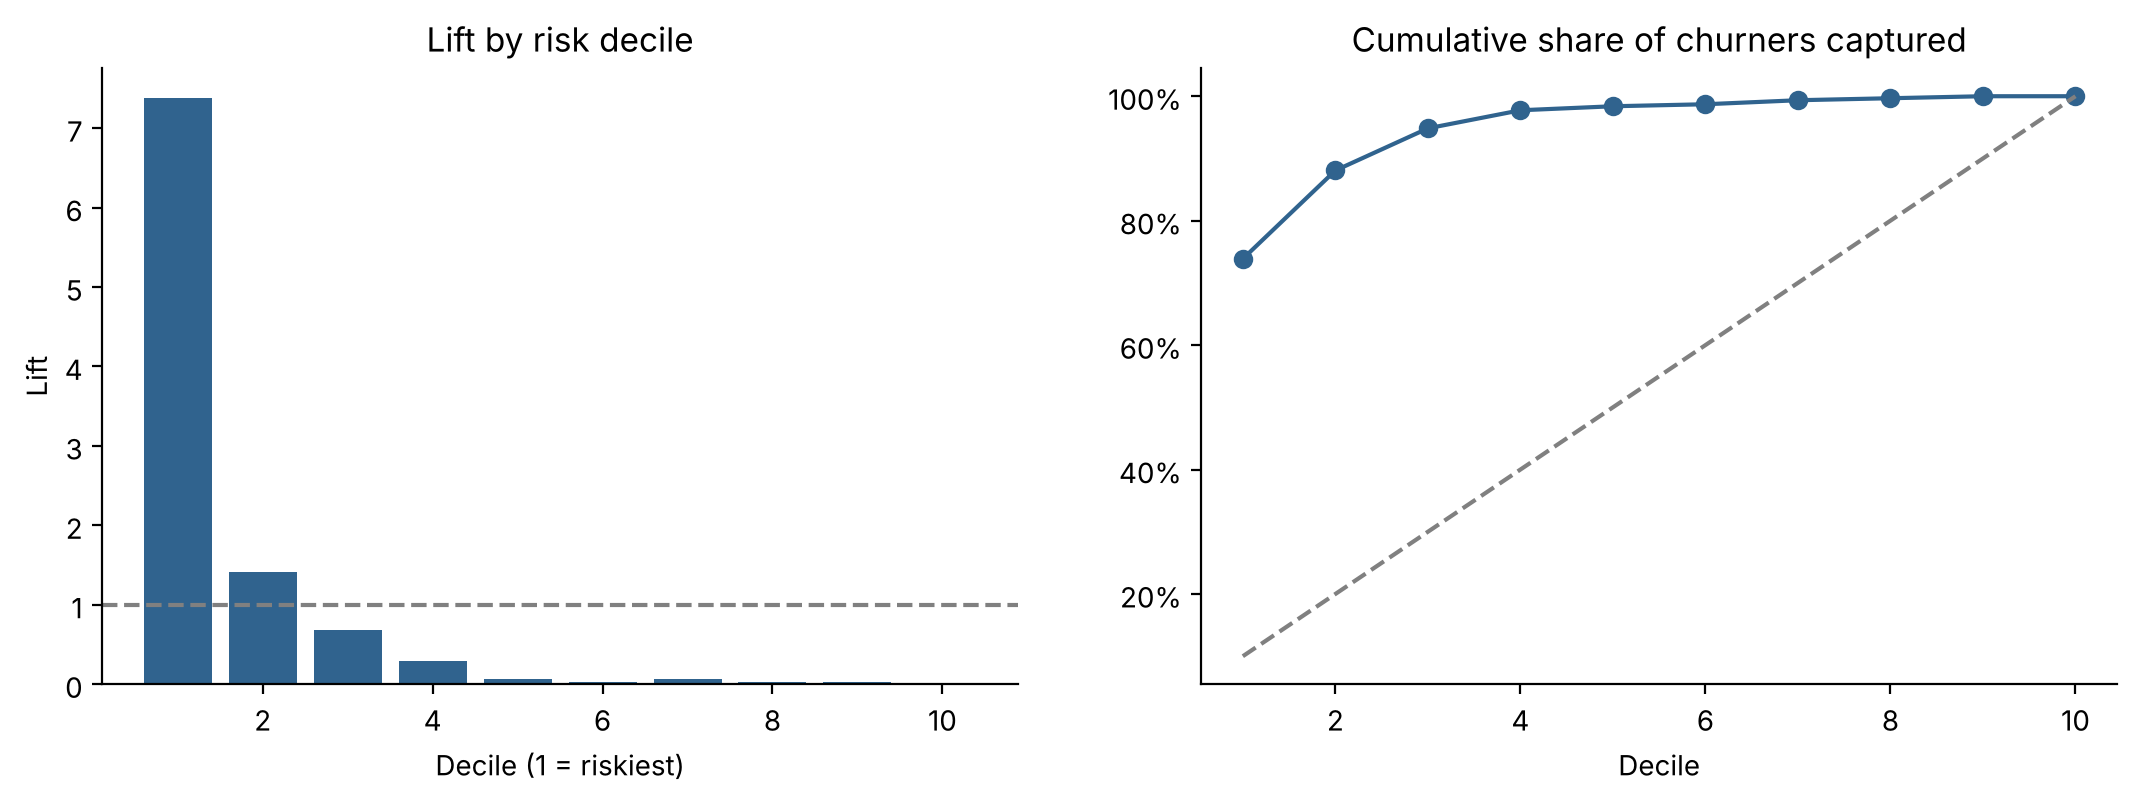

,decile,accounts,churners,avg_predicted,annual_revenue,churn_rate,lift,cum_share_of_churners
0,1,625,229,0.406,"10,077,743.040",0.366,7.385,0.739
1,2,625,44,0.050,"10,549,170.840",0.070,1.419,0.881
2,3,625,21,0.019,"11,770,654.080",0.034,0.677,0.948
3,4,624,9,0.008,"11,626,607.160",0.014,0.291,0.977
4,5,625,2,0.004,"12,845,652.840",0.003,0.064,0.984
5,6,625,1,0.003,"13,174,968.600",0.002,0.032,0.987
6,7,624,2,0.002,"16,197,129.600",0.003,0.065,0.994
7,8,625,1,0.001,"20,814,048.960",0.002,0.032,0.997
8,9,625,1,0.001,"26,936,234.640",0.002,0.032,1.000
9,10,625,0,0.001,"36,773,973.720",0.000,0.000,1.000


In [11]:
lift = pd.read_csv(ARTIFACTS_DIR / "lift_table.csv")
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.bar(lift["decile"], lift["lift"], color="#30638E"); a.axhline(1, ls="--", c="grey")
a.set(title="Lift by risk decile", xlabel="Decile (1 = riskiest)", ylabel="Lift")
b.plot(lift["decile"], lift["cum_share_of_churners"], marker="o", color="#30638E")
b.plot(lift["decile"], lift["decile"] / 10, ls="--", c="grey")
b.set(title="Cumulative share of churners captured", xlabel="Decile")
b.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()
lift

**Business reading:** the retention team only needs to work the riskiest 10% of business accounts to reach
about **74% of the accounts that will leave**, about 7.4× better than random. LightGBM beats the logistic
regression baseline on every metric, most clearly in the riskiest 20% of accounts.

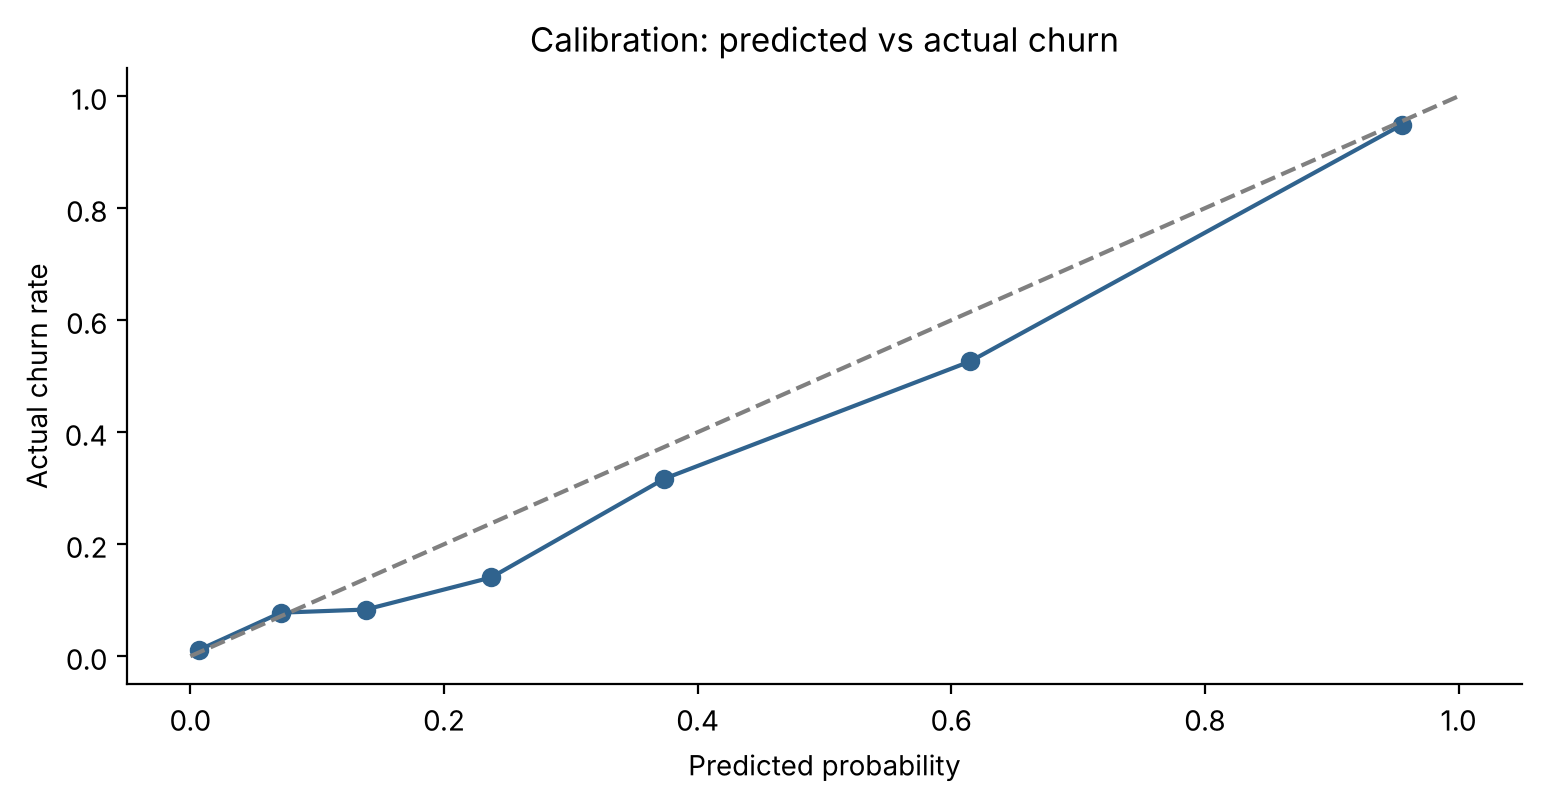

,bin,predicted,actual,accounts
0,"(-0.001, 0.05]",0.007,0.011,5347
1,"(0.05, 0.1]",0.071,0.078,347
2,"(0.1, 0.2]",0.138,0.083,252
3,"(0.2, 0.3]",0.237,0.141,64
4,"(0.3, 0.5]",0.374,0.317,41
5,"(0.5, 0.7]",0.615,0.526,19
6,"(0.7, 1.0]",0.956,0.949,178


In [12]:
calib = pd.read_csv(ARTIFACTS_DIR / "calibration.csv")
plt.plot(calib["predicted"], calib["actual"], marker="o", color="#30638E")
plt.plot([0, 1], [0, 1], ls="--", c="grey"); plt.title("Calibration: predicted vs actual churn")
plt.xlabel("Predicted probability"); plt.ylabel("Actual churn rate"); plt.show()
calib

## 6. Explainability with SHAP

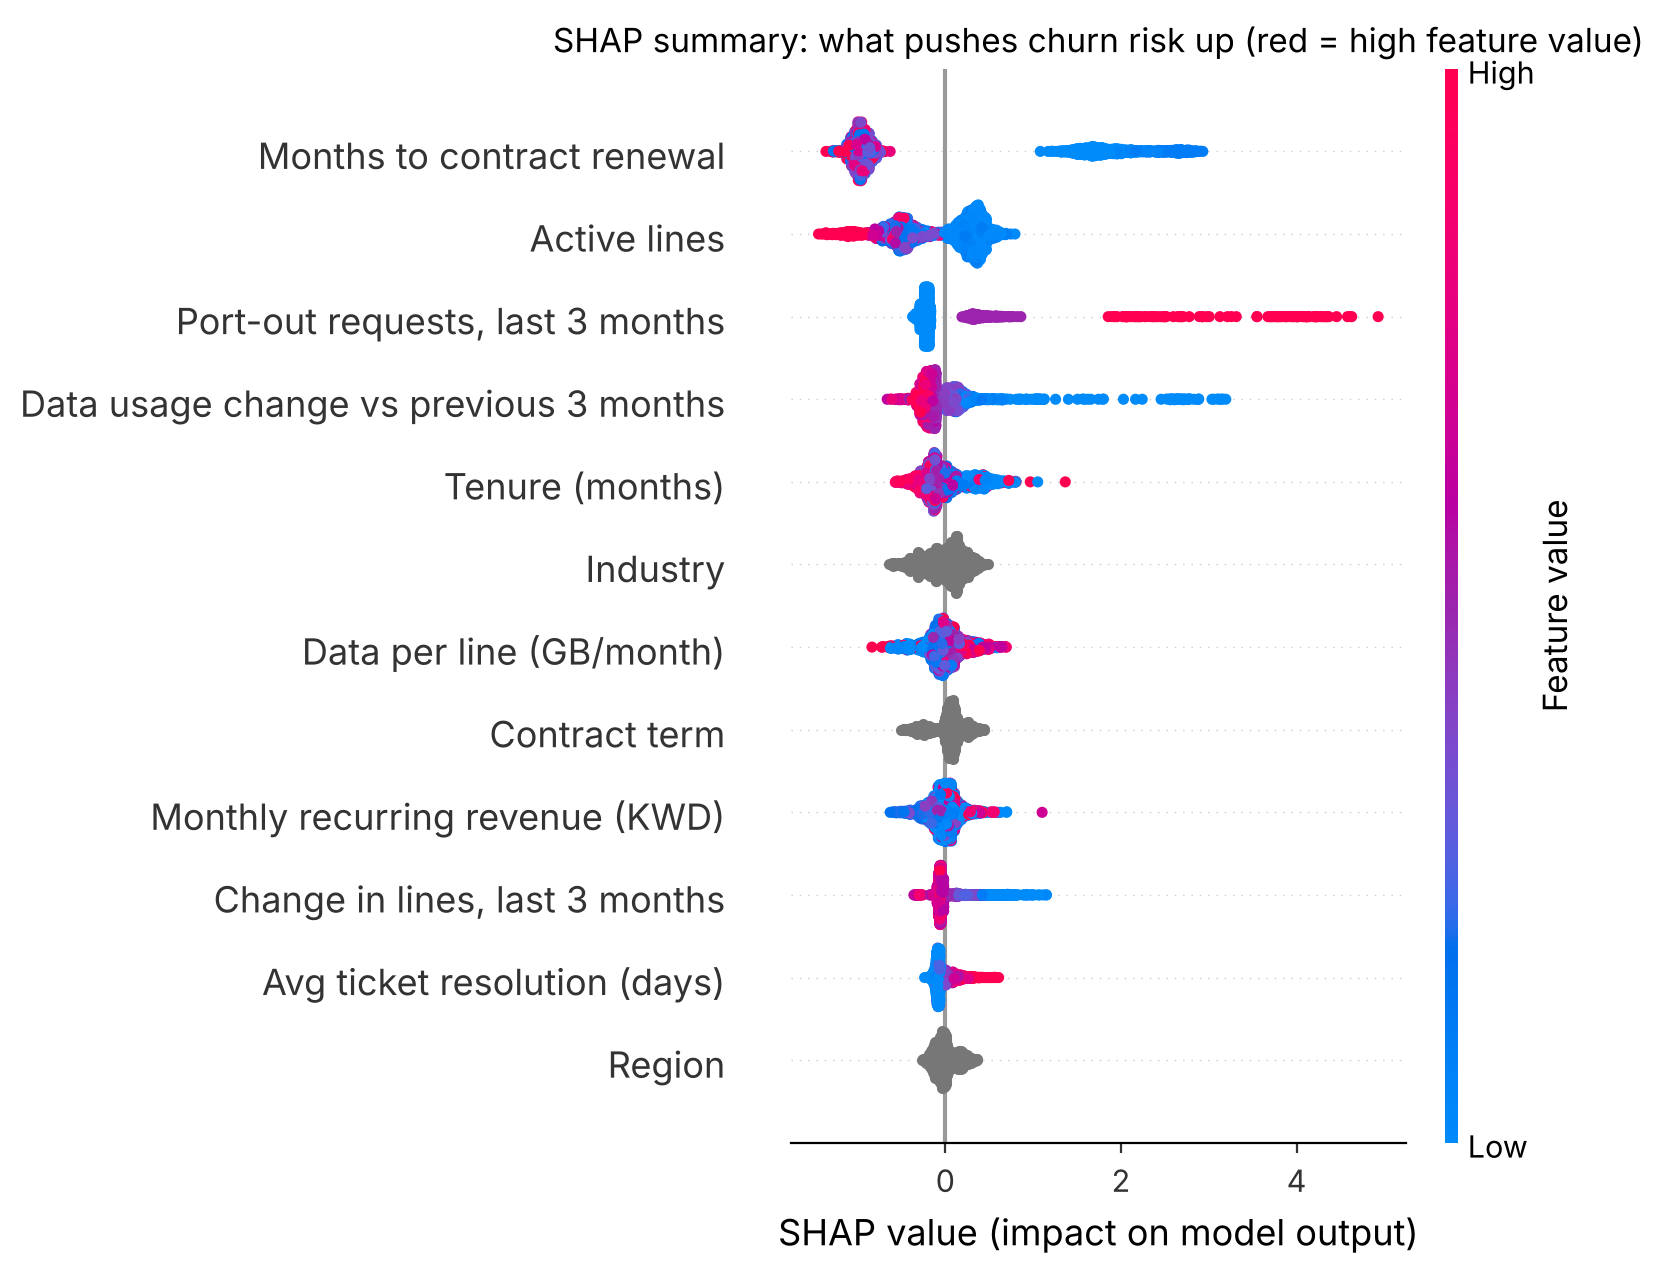

In [13]:
import shap
from src.model_utils import load_bundle, prepare_X
bundle = load_bundle()
model, categories = bundle["model"], bundle["categories"]
sample = data[data["snapshot_date"] >= TEST_SNAPSHOT_START].sample(2000, random_state=1)
X = prepare_X(sample, categories)
sv = shap.TreeExplainer(model).shap_values(X)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, X.rename(columns=FEATURE_LABELS), show=False, max_display=12)
plt.title("SHAP summary: what pushes churn risk up (red = high feature value)"); plt.show()

Each dot is one account-month. **Few months to renewal** and **port-out requests** push risk up the most, followed by falling data usage. Larger accounts (more lines) and long remaining contract terms push risk **down**. These same per-account values drive the "top 3 reasons" shown in the app and in Power BI.

## 7. Score current accounts
`src/score.py` is the batch job that would run monthly, after the billing cycle closes.

In [14]:
from src import score
score.main()
scores = pd.read_csv(ARTIFACTS_DIR / "churn_scores.csv")
scores[["company_name", "segment", "contract_term", "months_to_renewal", "active_lines",
        "churn_probability", "risk_band", "revenue_at_risk", "reason_1", "reason_2"]].head(10)

Scored 834 active accounts as of 2026-10-31
risk_band
Low       785
Medium     28
High       21
Revenue at risk (annualised): KWD 654,324
Lines at risk: 4,801
           company_name  churn_probability risk_band                               reason_1
0          Bay Works 96              0.955      High   7 port-out requests in last 3 months
1      Nova Partners 74              0.676      High   3 port-out requests in last 3 months
2     Coral Partners 81              0.430      High             Contract renews in 1 month
3        Nova Supply 98              0.336    Medium            Contract renews in 3 months
4  Granite Solutions 35              0.330    Medium             Contract renews in 1 month
5       Vertex Group 77              0.456      High            Contract renews in 2 months
6   Horizon Holdings 79              0.993      High  10 port-out requests in last 3 months
7   Delta Industries 13              0.253    Medium            Contract renews in 3 months


,company_name,segment,contract_term,months_to_renewal,active_lines,churn_probability,risk_band,revenue_at_risk,reason_1,reason_2
0,Bay Works 96,Enterprise,24 months,2,"1,116.000",0.955,High,"137,762.980",7 port-out requests in last 3 months,Contract renews in 2 months
1,Nova Partners 74,Enterprise,24 months,17,363.000,0.676,High,"40,481.840",3 port-out requests in last 3 months,Lines down 13% in last 3 months
2,Coral Partners 81,Enterprise,24 months,1,690.000,0.430,High,"39,884.800",Contract renews in 1 month,2 port-out requests in last 3 months
3,Nova Supply 98,Enterprise,24 months,3,724.000,0.336,Medium,"37,382.460",Contract renews in 3 months,Data usage down 14% vs previous quarter
4,Granite Solutions 35,Enterprise,24 months,1,787.000,0.330,Medium,"24,800.440",Contract renews in 1 month,Customer for 95 months
5,Vertex Group 77,Government,24 months,2,335.000,0.456,High,"18,759.000",Contract renews in 2 months,Lines down 7% in last 3 months
6,Horizon Holdings 79,Corporate,24 months,2,146.000,0.993,High,"18,171.420",10 port-out requests in last 3 months,Data usage down 31% vs previous quarter
7,Delta Industries 13,Enterprise,12 months,3,485.000,0.253,Medium,"17,619.040",Contract renews in 3 months,1 port-out requests in last 3 months
8,Gulf Services 93,Corporate,12 months,2,100.000,0.966,High,"17,386.530",4 port-out requests in last 3 months,Contract renews in 2 months
9,Coral Holdings 38,Enterprise,12 months,3,739.000,0.167,Medium,"16,776.030",Contract renews in 3 months,1 port-out requests in last 3 months


## Next steps
- Agree risk-band thresholds with the retention team based on how many accounts they can work each month
- Predict **partial churn** too (large drops in lines without full termination)
- Add competitor-offer signals, NPS surveys and network KPIs per site
- Track predicted vs actual churn monthly and retrain quarterly